# multimodel_analysis v0.1.4 - Phase 1 results
This notebook exercises the bug fixes: input validation, full confusion matrices, numeric ROC AUC, recorded warnings/failed models, KNN regressor and the new defaults.

In [1]:
%matplotlib inline
import warnings
import numpy as np, pandas as pd
from sklearn.datasets import load_iris, load_breast_cancer, make_regression
import multimodel_analysis as mm
from multimodel_analysis import MultiModelClassifier, MultiModelRegressor
print(mm.__version__)

0.2.0.dev0


## 1. Multiclass classification (Iris, string labels)

In [2]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target.map(dict(enumerate(iris.target_names)))
clf = MultiModelClassifier(X, y, random_state=42)
models = clf.run_all_models()
df = clf.show_tabular_report(models, return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC
                SVM  0.933333   0.934524 0.933333  0.933259 0.995556
                KNN  0.933333   0.944444 0.933333  0.932660 0.994815
  Gradient Boosting  0.933333   0.944444 0.933333  0.932660 0.998519
           AdaBoost  0.933333   0.934524 0.933333  0.933259 0.980741
      Decision Tree  0.911111   0.915535 0.911111  0.910714 0.933333
Logistic Regression  0.911111   0.915535 0.911111  0.910714 0.995556
        Naive Bayes  0.911111   0.915535 0.911111  0.910714 0.985185
      Random Forest  0.888889   0.898148 0.888889  0.887767 0.992593

* BEST MODEL RECOMMENDATION (by Accuracy): SVM
   Accuracy: 0.9333 | F1 Score: 0.9333



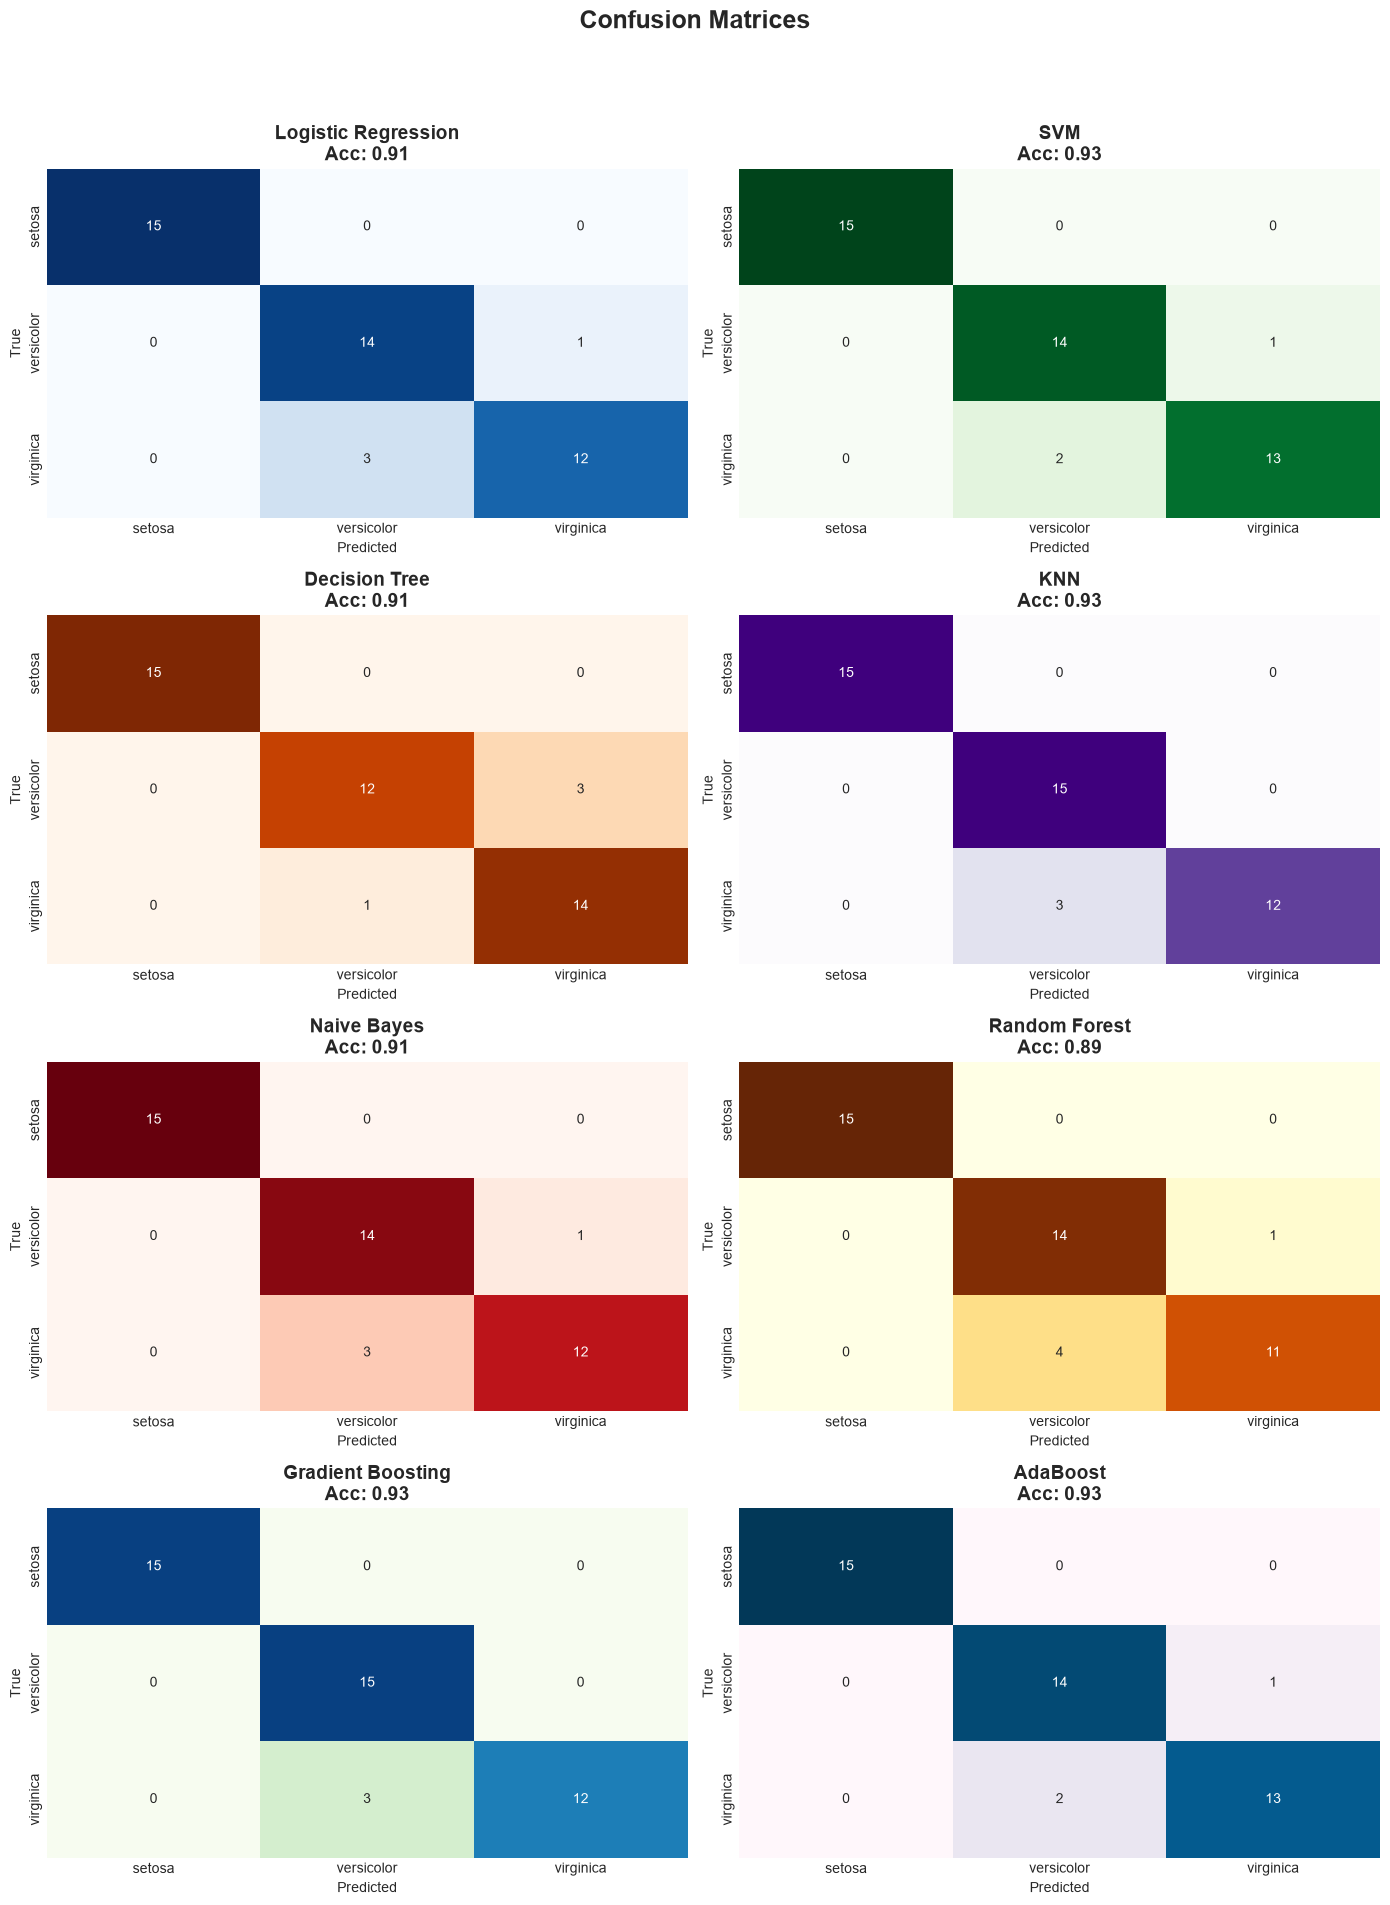

In [3]:
clf.plot_confusion_matrices(models)

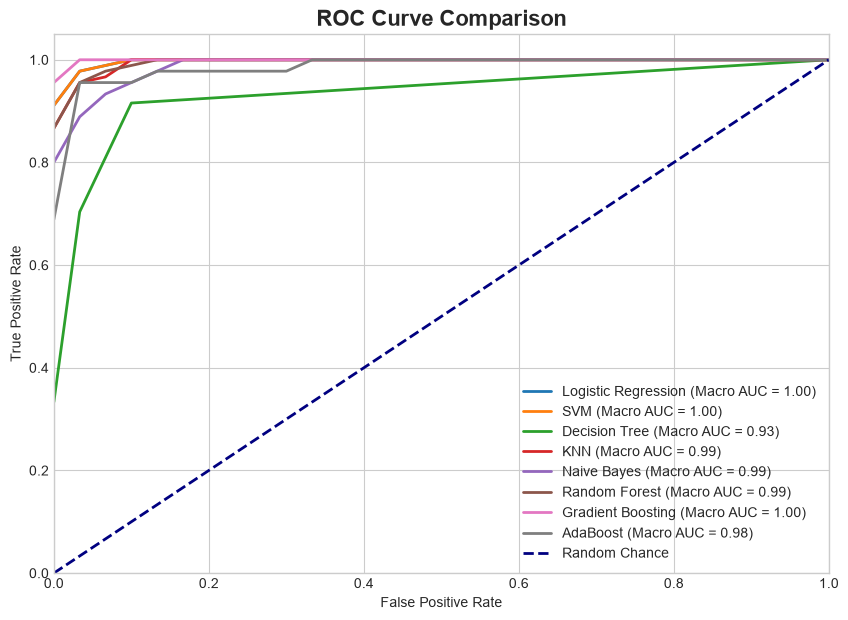

In [4]:
clf.plot_roc_curves(models)

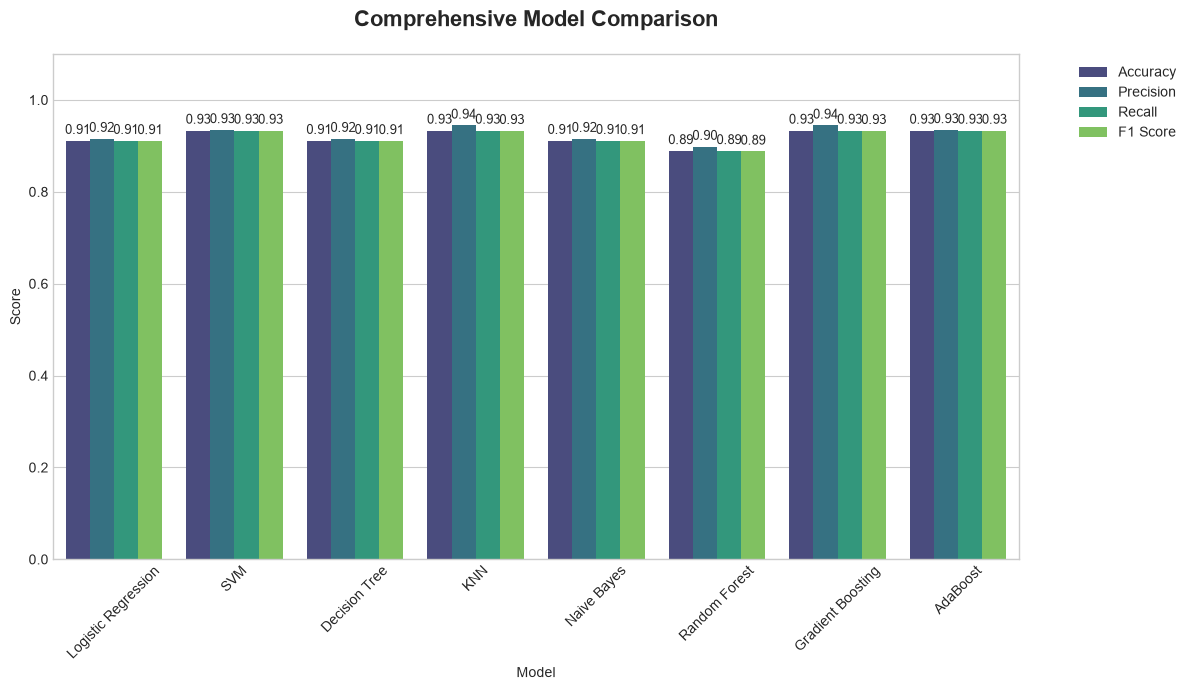

In [5]:
clf.plot_comparison(models)

## 2. Binary classification (Breast cancer) sorted by ROC AUC

In [6]:
bc = load_breast_cancer(as_frame=True)
clf2 = MultiModelClassifier(bc.data, bc.target, random_state=0)
clf2.run_all_models()
clf2.show_tabular_report(sort_by='ROC AUC', return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC
Logistic Regression  0.959064   0.959259 0.959064  0.959127 0.995619
                SVM  0.953216   0.953216 0.953216  0.953216 0.992699
           AdaBoost  0.941520   0.941520 0.941520  0.941520 0.989048
                KNN  0.935673   0.935639 0.935673  0.935345 0.987150
  Gradient Boosting  0.935673   0.935936 0.935673  0.935771 0.986273
      Random Forest  0.953216   0.953187 0.953216  0.953062 0.978023
        Naive Bayes  0.912281   0.912614 0.912281  0.912415 0.975321
      Decision Tree  0.906433   0.908510 0.906433  0.906959 0.906396

* BEST MODEL RECOMMENDATION (by ROC AUC): Logistic Regression
   Accuracy: 0.9591 | F1 Score: 0.9591



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.959064,0.959259,0.959064,0.959127,0.995619
1,SVM,0.953216,0.953216,0.953216,0.953216,0.992699
2,AdaBoost,0.941520,0.941520,0.941520,0.941520,0.989048
3,KNN,0.935673,0.935639,0.935673,0.935345,0.987150
4,Gradient Boosting,0.935673,0.935936,0.935673,0.935771,0.986273
5,Random Forest,0.953216,0.953187,0.953216,0.953062,0.978023
6,Naive Bayes,0.912281,0.912614,0.912281,0.912415,0.975321
7,Decision Tree,0.906433,0.908510,0.906433,0.906959,0.906396


## 3. Failures and warnings are recorded, not hidden

In [7]:
class Broken:
    def fit(self, X, y):
        raise RuntimeError('boom')

m = clf2.run_all_models(custom_models={'Broken model': Broken()})
print('failed:', clf2.failed_models_)
print('warnings:', clf2.warnings_)

[WARNING] Custom model 'Broken model' failed: boom
failed: {'Broken model': 'RuntimeError: boom'}
warnings: {'SVM': ['FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`']}


## 4. Clear errors for bad input

In [8]:
for label, args in {
    'continuous target': (X, np.random.rand(len(X))),
    'length mismatch': (X, y[:-5]),
    'NaN in X': (X.assign(**{X.columns[0]: np.where(np.arange(len(X)) == 0, np.nan, X.iloc[:, 0])}), y),
}.items():
    try:
        MultiModelClassifier(*args)
    except Exception as e:
        print(f'{label:18s} -> {type(e).__name__}: {e}'); print()

continuous target  -> ValueError: The target 'y' looks continuous (real-valued), which is a regression problem. Use MultiModelRegressor, or convert y to class labels before using MultiModelClassifier.

length mismatch    -> ValueError: X and y have different lengths: X has 150 rows but y has 145 values.

NaN in X           -> ValueError: X contains 1 missing (NaN) or infinite value(s). Impute or drop them first (e.g. X.fillna(X.median())).



## 5. Regression (now with KNN Regressor; SVR target-scaled)

In [9]:
Xr, yr = make_regression(n_samples=300, n_features=8, noise=10, random_state=1)
reg = MultiModelRegressor(Xr, yr, random_state=1)
rm = reg.run_all_models()
reg.show_tabular_report(rm, sort_by='RMSE', return_df=True)


 REGRESSION MODEL COMPARISON TABLE 
                      Model        MAE          MSE       RMSE  R2 Score
          Linear Regression   7.824985    91.034435   9.541197  0.997713
           Lasso Regression   7.878036    91.713250   9.576704  0.997696
           Ridge Regression   7.997994    93.305211   9.659462  0.997656
                        SVR  37.928997  3744.235476  61.190158  0.905932
Gradient Boosting Regressor  50.714961  4581.490580  67.686709  0.884897
              KNN Regressor  72.312597  9122.683519  95.512740  0.770807
    Random Forest Regressor  79.507840  9926.535405  99.632000  0.750611
         AdaBoost Regressor  84.337263 11790.890247 108.585866  0.703772
    Decision Tree Regressor 120.032032 23680.705730 153.885366  0.405059

* BEST MODEL RECOMMENDATION (by RMSE): Linear Regression
   R2 Score: 0.9977 | RMSE: 9.5412



,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,7.824985,91.034435,9.541197,0.997713
1,Lasso Regression,7.878036,91.713250,9.576704,0.997696
2,Ridge Regression,7.997994,93.305211,9.659462,0.997656
3,SVR,37.928997,3744.235476,61.190158,0.905932
4,Gradient Boosting Regressor,50.714961,4581.490580,67.686709,0.884897
5,KNN Regressor,72.312597,9122.683519,95.512740,0.770807
6,Random Forest Regressor,79.507840,9926.535405,99.632000,0.750611
7,AdaBoost Regressor,84.337263,11790.890247,108.585866,0.703772
8,Decision Tree Regressor,120.032032,23680.705730,153.885366,0.405059


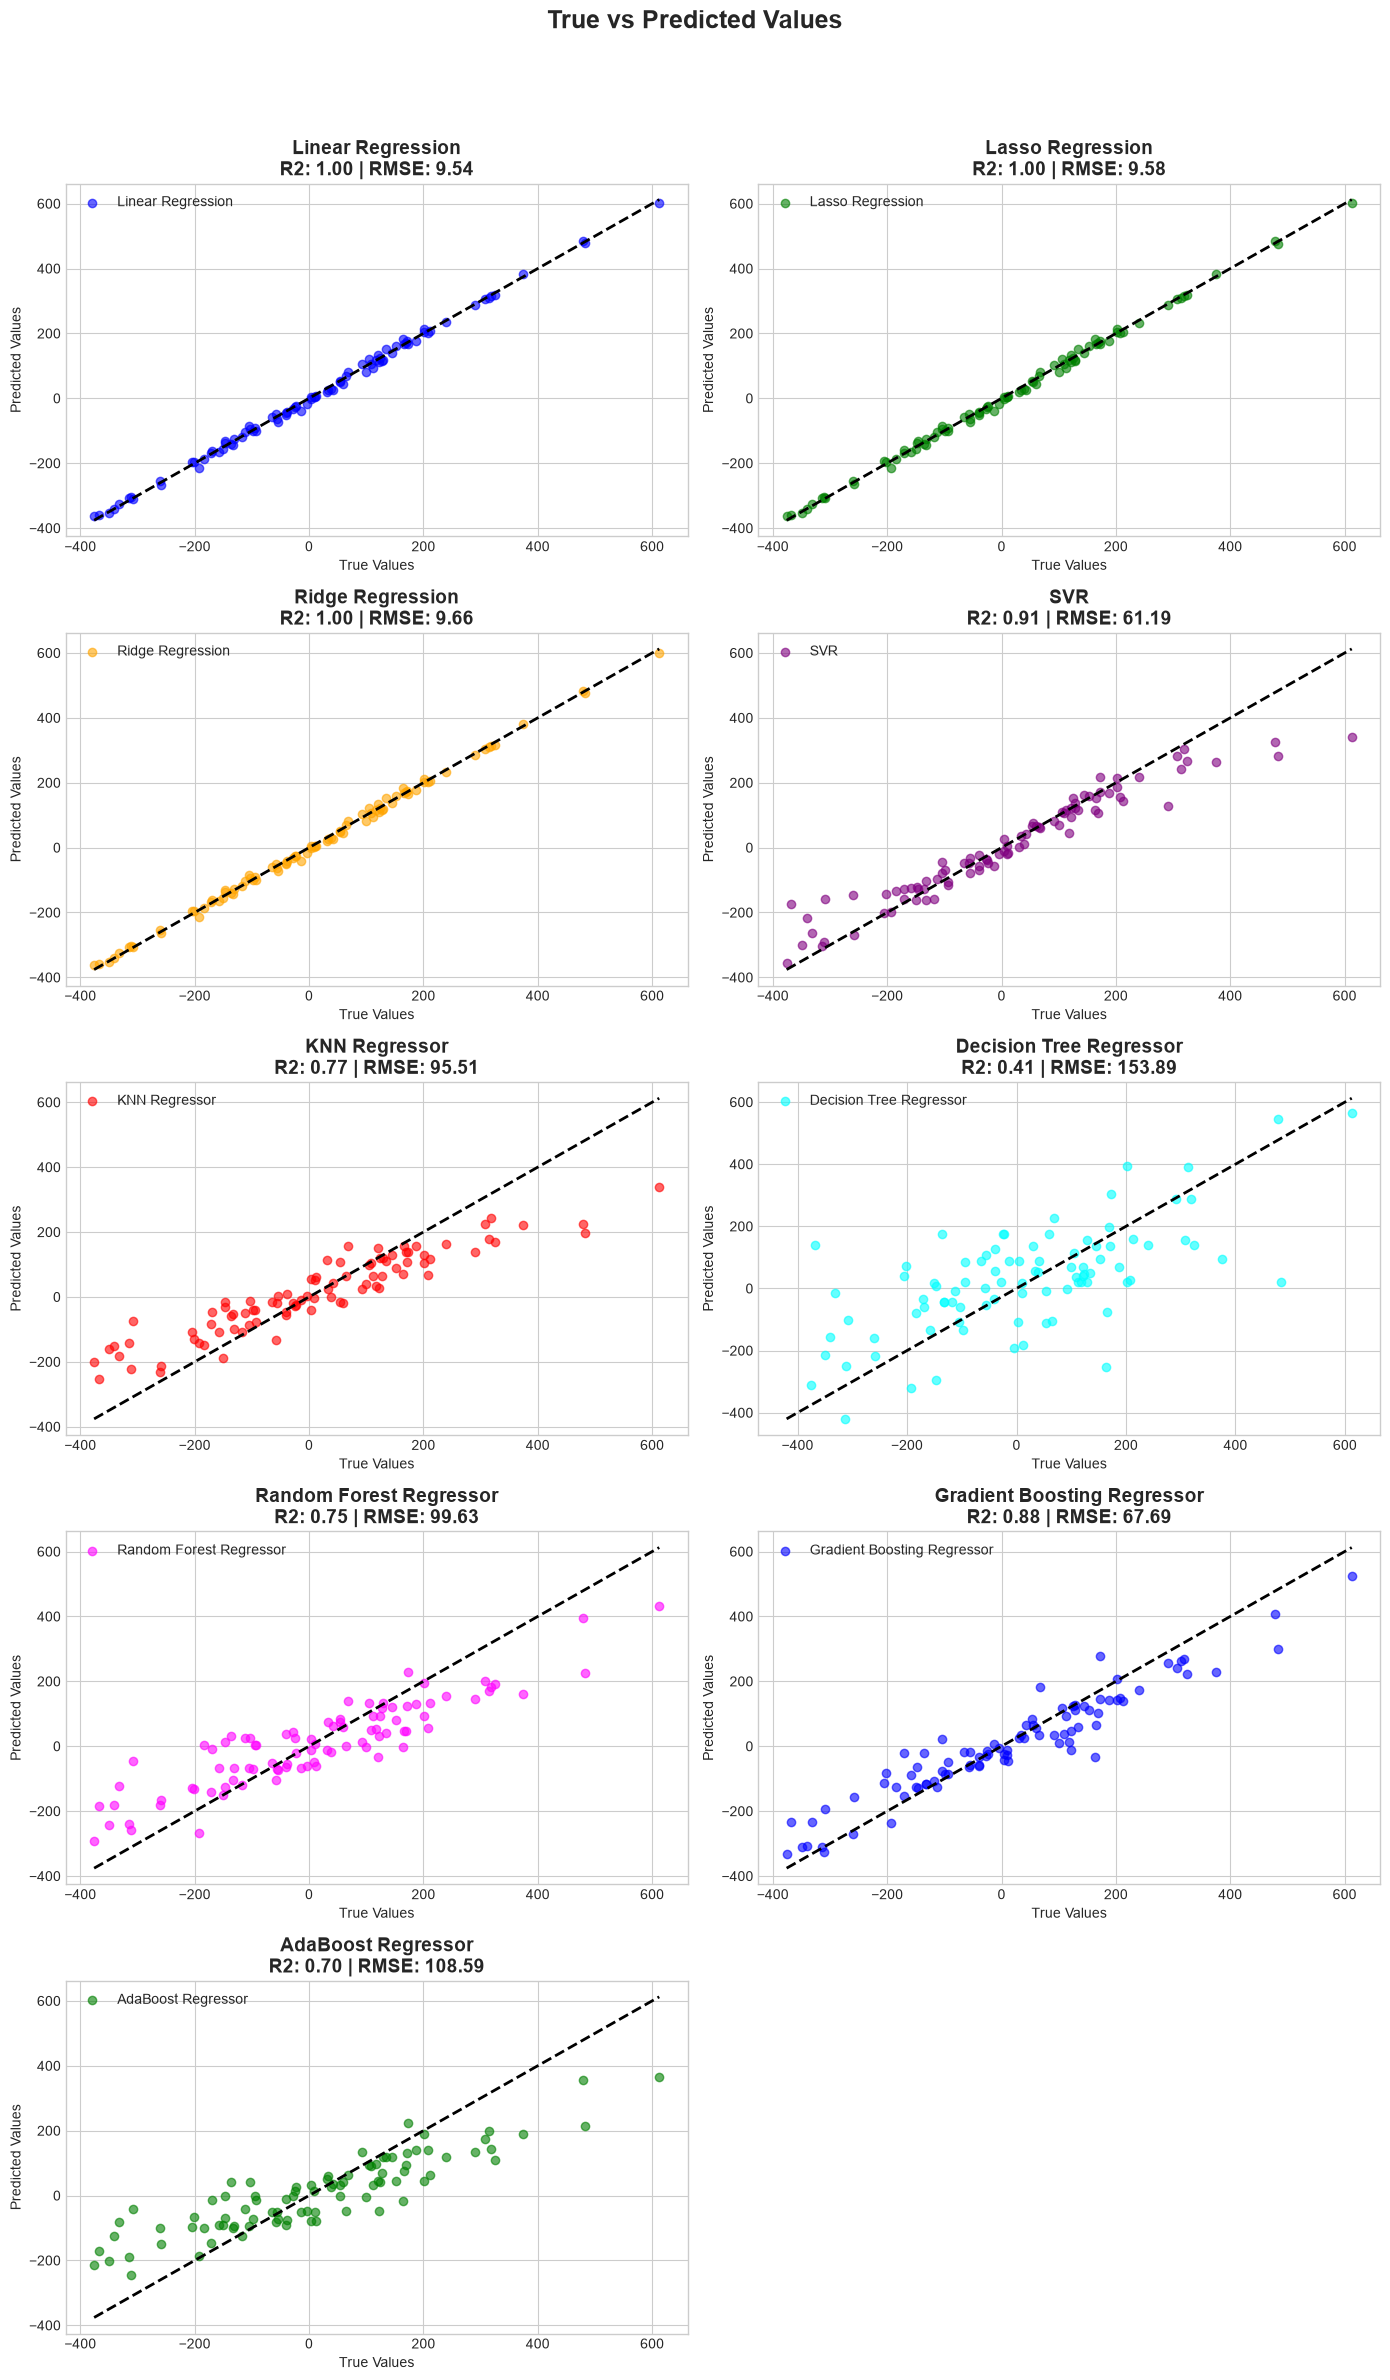

In [10]:
reg.plot_true_vs_predicted(rm)

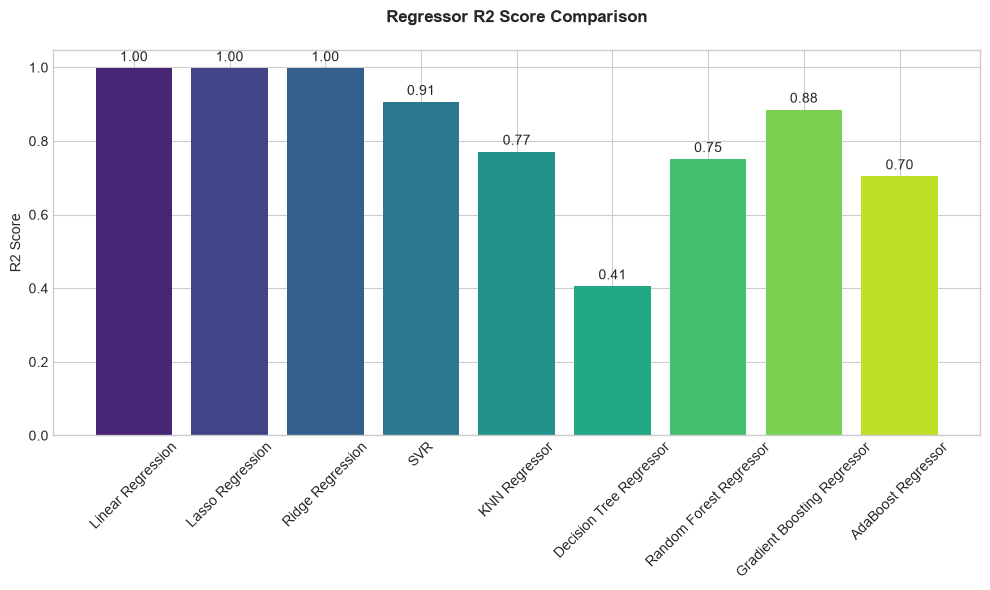

In [11]:
reg.plot_comparison(rm)